## Análisis - Insights

Discusión crítica del proceso y verdades al juntar las técnicas

### Imports

In [1]:
import os, socket
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)

### Utilidades

- Constantes

In [2]:
proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent
out_dir = proyecto / "06_Analisis" / "temp" / "c_insights"
out_dir.mkdir(parents=True, exist_ok=True)

- Lectura de resultados

In [3]:
def leer(modulo, nb, tabla):
    ruta = proyecto / modulo / "temp" / nb / "tablas" / tabla
    assert ruta.exists(), f"No se encuentra {ruta}; corre {modulo}/{nb}.ipynb"
    return spark.read.parquet(str(ruta)).toPandas()

- Figuras y tablas

In [ ]:
def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()


def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()


def dirs_salida(out_dir):
    fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
    for d in (fig_dir, tab_dir, web_dir):
        d.mkdir(parents=True, exist_ok=True)
    return fig_dir, tab_dir, web_dir


fig_dir, tab_dir, web_dir = dirs_salida(out_dir)

- Spark

In [5]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName("analisis-insights")
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "2g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "2g"))
           .config("spark.sql.shuffle.partitions", "8")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

### Verificación del cluster

In [6]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

---
### 1. ¿Qué técnicas aportaron más valor?

In [7]:
valor = pd.DataFrame([
    {"tecnica": "MinHash + LSH", "pregunta": "P2", "valor": "alto",
     "aporte": "Encontró 131k pares casi idénticos entre 3.3M posibles y el patrón OEFA (90% de los procesos exclusivos)",
     "limitacion": "Similar no prueba fraccionamiento; depende de filtros de negocio posteriores"},
    {"tecnica": "Reglas (Apriori / FP-Growth)", "pregunta": "P1", "valor": "alto",
     "aporte": "Formalizó combinaciones: método + monto llega a 93.6% de postor único (vs 86.6% el método solo)",
     "limitacion": "Muchas reglas obvias o normativas (rubro 72 → obras, > 5M → Licitación Pública)"},
    {"tecnica": "Bloom / Count-Min", "pregunta": "P1", "valor": "medio",
     "aporte": "Reincidencia 19% → 41% y su relación con postor único (16.3% vs 11.9%); 16 heavy hitters",
     "limitacion": "Con 184k llegadas un set/dict exacto cabe en memoria; su valor real es a mayor escala"},
    {"tecnica": "DGIM", "pregunta": "P1", "valor": "medio",
     "aporte": "Estacionalidad: picos en enero/diciembre y valles en abril/noviembre",
     "limitacion": "La ventana elegida cambia qué picos se ven; el EDA mensual ya lo insinuaba"},
    {"tecnica": "TF-IDF + IVF / HNSW", "pregunta": "P3", "valor": "medio",
     "aporte": "Mostró que la variación es por entidad (escala de compra) y no por región",
     "limitacion": "Sin cantidad ni precio unitario no da precios de referencia directos"},
])
valor[["tecnica", "pregunta", "valor", "aporte", "limitacion"]]

,tecnica,pregunta,valor,aporte,limitacion
0,MinHash + LSH,P2,alto,Encontró 131k pares casi idénticos entre 3.3M posibles y el patrón OEFA (90%...,Similar no prueba fraccionamiento; depende de filtros de negocio posteriores
1,Reglas (Apriori / FP-Growth),P1,alto,Formalizó combinaciones: método + monto llega a 93.6% de postor único (vs 86...,"Muchas reglas obvias o normativas (rubro 72 → obras, > 5M → Licitación Pública)"
2,Bloom / Count-Min,P1,medio,Reincidencia 19% → 41% y su relación con postor único (16.3% vs 11.9%); 16 h...,Con 184k llegadas un set/dict exacto cabe en memoria; su valor real es a may...
3,DGIM,P1,medio,Estacionalidad: picos en enero/diciembre y valles en abril/noviembre,La ventana elegida cambia qué picos se ven; el EDA mensual ya lo insinuaba
4,TF-IDF + IVF / HNSW,P3,medio,Mostró que la variación es por entidad (escala de compra) y no por región,Sin cantidad ni precio unitario no da precios de referencia directos


- **Similitud y reglas.** LSH hace posibles las comparaciones y descubrió casos concreto (OEFA)

- **Flujos.** Confirman y ordenan en el tiempo lo que la exploración mostraba

- **ANN:** encuentra bien compras parecidas, pero el monto total sin cantidad impide hablar de precio por unidad

- **Adelanto** el método de contratación explica casi todo el postor único

### 2. ¿Cuánta precisión se pierde?

In [8]:
resumen_tec = leer("06_Analisis", "a_recuento", "tecnicas_resumen")
configs = leer("02_Similitud", "b_lsh", "configs_br")
var_p3 = leer("03_ANN", "e_analisis", "variacion_p3")
bloom = leer("04_Flujos", "b_bloom", "variacion")
bloom_k = bloom.loc[bloom.groupby("bits_por_par")["reincidencia"].apply(lambda s: (s - bloom["reincidencia_exacta"].iloc[0]).abs().idxmin())]
resumen_tec[["tecnica", "pregunta", "ahorro_x", "tipo_ahorro", "metrica_error", "error"]]

,tecnica,pregunta,ahorro_x,tipo_ahorro,metrica_error,error
0,MinHash (T=100),P2,1.0,—,error medio vs Jaccard,0.0314
1,"LSH (10, 10)",P2,20.3,comparaciones,recall,0.9999
2,IVF propio (Spark),P3,14.7,tiempo,recall@10,0.7500
3,IVF (faiss),P3,3.8,tiempo,recall@10,0.8923
4,HNSW (faiss),P3,20.9,tiempo,recall@10,0.9799
5,DGIM,P1,20.4,memoria,error relativo medio,0.1089
6,Bloom Filter,P1,135.0,memoria,tasa de falsos positivos (final),0.0102
7,Count-Min Sketch,P1,34.7,memoria,sobreestimación media (apariciones),1.9812


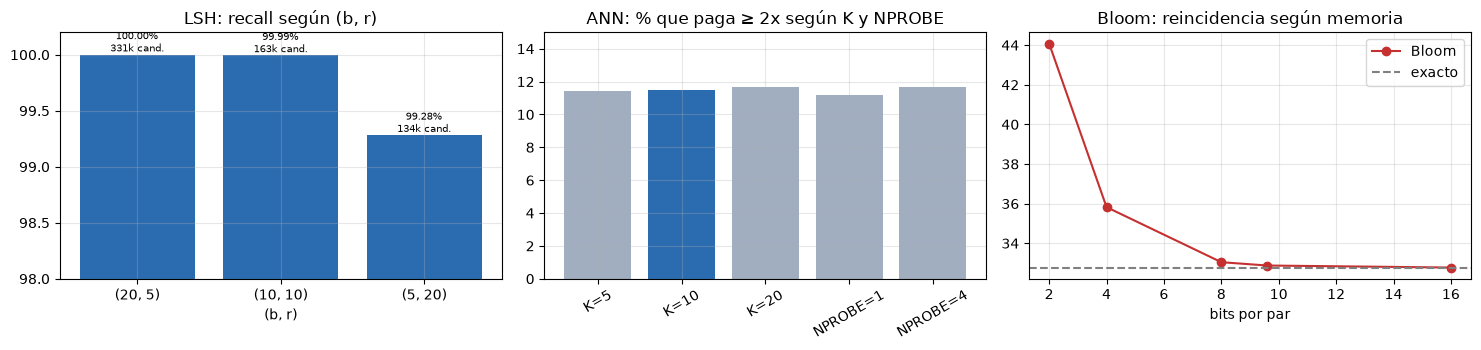

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
etq = [f"({b}, {r})" for b, r in zip(configs["b"], configs["r"])]
ax[0].bar(etq, configs["recall"] * 100, color="#2b6cb0"); ax[0].set_ylim(98, 100.2)
for x_, (v, c_) in enumerate(zip(configs["recall"], configs["candidatos"])):
    ax[0].annotate(f"{v:.2%}\n{c_ / 1e3:,.0f}k cand.", (x_, v * 100), ha="center", va="bottom", fontsize=7)
ax[0].set_title("LSH: recall según (b, r)"); ax[0].set_xlabel("(b, r)")
e_ = [f"{p}={v}" for p, v in zip(var_p3["parametro"], var_p3["valor"])]
ax[1].bar(e_, var_p3["pct_paga_2x"], color=["#2b6cb0" if e else "#a0aec0" for e in var_p3["elegido"]]); ax[1].set_ylim(0, 15)
ax[1].set_title("ANN: % que paga ≥ 2x según K y NPROBE"); ax[1].tick_params(axis="x", rotation=30)
ax[2].plot(bloom_k["bits_por_par"], bloom_k["reincidencia"], marker="o", color="#c53030", label="Bloom")
ax[2].axhline(bloom["reincidencia_exacta"].iloc[0], color="gray", ls="--", label="exacto")
ax[2].set_xlabel("bits por par"); ax[2].set_title("Bloom: reincidencia según memoria"); ax[2].legend()
mostrar_fig("precision_vs_ahorro")

- **Sí vale la pena:** con los parámetros elegidos el error no cambia ninguna respuesta

- **El riesgo está en quedarse corto de memoria:** con 2 bits por par, Bloom infla la reincidencia a 44–62%

- Diluye su relación con postor único; con w chico, Count-Min reporta miles de falsos heavy hitters

- **IVF con recall de 75% basta** porque los vecinos que importan (coseno ≥ 0.80) son los más fáciles de encontrar

### 3. ¿Qué tareas se beneficiaron de Spark?

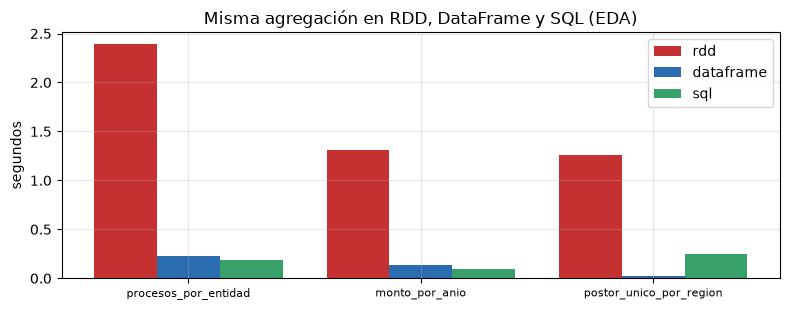

,etapa,motor,por_que
0,EDA y KDD,Spark,Aplanar JSON anidados de 36 meses y escribir parquet particionado por anio/mes
1,"Similitud (MinHash, LSH, pares)",Spark,Joins por banda y verificación de pares mes a mes; partition pruning por ani...
2,"ANN: TF-IDF, IVF, búsqueda",Spark,HashingTF/IDF y KMeans de MLlib sobre 236k vectores; búsqueda como join dist...
3,"ANN: faiss (IVF, HNSW)","Python, sin Spark",faiss trabaja en memoria de una máquina; muestra de 20k vectores
4,"Flujos (DGIM, Bloom, Count-Min)","Python, sin Spark",Un flujo es secuencial: cada llegada depende del estado anterior
5,Reglas: Apriori (Q4 2025),"Python, sin Spark",mlxtend en un trimestre; 90x más rápido que FP-Growth en Spark a esa escala
6,Reglas: FP-Growth (completo),Spark,MLlib sobre los 236k procesos sin codificar a matriz one-hot


In [10]:
tiempos = leer("01_EDA_KDD", "b_exploracion", "tiempos_rdd_df_sql")
donde_corre = pd.DataFrame([
    {"etapa": "EDA y KDD", "motor": "Spark", "por_que": "Aplanar JSON anidados de 36 meses y escribir parquet particionado por anio/mes"},
    {"etapa": "Similitud (MinHash, LSH, pares)", "motor": "Spark", "por_que": "Joins por banda y verificación de pares mes a mes; partition pruning por anio/mes"},
    {"etapa": "ANN: TF-IDF, IVF, búsqueda", "motor": "Spark", "por_que": "HashingTF/IDF y KMeans de MLlib sobre 236k vectores; búsqueda como join distribuido"},
    {"etapa": "ANN: faiss (IVF, HNSW)", "motor": "Python, sin Spark", "por_que": "faiss trabaja en memoria de una máquina; muestra de 20k vectores"},
    {"etapa": "Flujos (DGIM, Bloom, Count-Min)", "motor": "Python, sin Spark", "por_que": "Un flujo es secuencial: cada llegada depende del estado anterior"},
    {"etapa": "Reglas: Apriori (Q4 2025)", "motor": "Python, sin Spark", "por_que": "mlxtend en un trimestre; 90x más rápido que FP-Growth en Spark a esa escala"},
    {"etapa": "Reglas: FP-Growth (completo)", "motor": "Spark", "por_que": "MLlib sobre los 236k procesos sin codificar a matriz one-hot"},
])
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(tiempos)); w = .27
for k_, (col, c_) in enumerate([("rdd_s", "#c53030"), ("dataframe_s", "#2b6cb0"), ("sql_s", "#38a169")]):
    ax.bar(x + (k_ - 1) * w, tiempos[col], w, color=c_, label=col.replace("_s", ""))
ax.set_xticks(x); ax.set_xticklabels(tiempos["agregacion"], fontsize=8); ax.set_ylabel("segundos"); ax.legend()
ax.set_title("Misma agregación en RDD, DataFrame y SQL (EDA)")
mostrar_fig("spark")
donde_corre

- **Spark se justificó en lo que mueve todo el dataset:** aplanar los JSON, los joins de LSH y la búsqueda IVF

- **DataFrame/SQL ganaron siempre a RDD**: el optimizador y el formato columnar pesan más que el paralelismo

- **No aporta en tareas chicas o secuenciales:** Apriori fue 90x más rápido que FP-Growth en Spark sobre Q4 2025

### 4. ¿Cambiara con mas datos?

Pares y comparaciones crecen con el cuadrado de los procesos por entidad, el resto de forma lineal o fija

In [11]:
base = {"fuerza bruta de pares (P2)": (3_312_072, 2, "pares"), "candidatos LSH (P2)": (163_482, 1, "pares"),
        "comparaciones IVF por consulta (P3)": (127_314_108 / 20_062, 1, "vectores"), "memoria HNSW, todos los procesos (P3)": (312 * 235_954 / 20_000, 1, "MB"),
        "memoria Bloom (P1)": (148_414 / 1024, 1, "KB"), "memoria Count-Min (P1)": (667_800 / 1024, 0, "KB"),
        "memoria DGIM (P1)": (40.4, 0, "bytes")}
escalamiento = pd.DataFrame([{"recurso": k_, "unidad": u, "actual": v, "x10": v * 10 ** e, "x100": v * 100 ** e,
                              "crece": {2: "cuadrático", 1: "lineal", 0: "fijo / log"}[e]} for k_, (v, e, u) in base.items()])
escalamiento.assign(**{c: escalamiento[c].map("{:,.0f}".format) for c in ["actual", "x10", "x100"]})

,recurso,unidad,actual,x10,x100,crece
0,fuerza bruta de pares (P2),pares,"3,312,072","331,207,200","33,120,720,000",cuadrático
1,candidatos LSH (P2),pares,"163,482","1,634,820","16,348,200",lineal
2,comparaciones IVF por consulta (P3),vectores,"6,346","63,460","634,603",lineal
3,"memoria HNSW, todos los procesos (P3)",MB,"3,681","36,809","368,088",lineal
4,memoria Bloom (P1),KB,145,"1,449","14,494",lineal
5,memoria Count-Min (P1),KB,652,652,652,fijo / log
6,memoria DGIM (P1),bytes,40,40,40,fijo / log


- **La fuerza bruta deja de ser posible:** de 3.3M a ~330M de pares con 10x; LSH crece lineal y sigue viable

- **HNSW deja de caber en una máquina:** ~3.7 GB con los 236k procesos, ~37 GB con 10x y ~370 GB con 100x

- **Flujos:** Bloom crece con los pares distintos (1.4 MB con 10x), Count-Min y DGIM quedan fijos

- **Apriori deja de ser viable** y FP-Growth en Spark pasa a ser necesario

- **Algunas decisiones cambian solas:** con más años, `filtro_meses` (mes + siguiente) sigue acotando LSH

- Con más datos por mes, habría que bajar la ventana o subir `r`/`b` para mantener los candidatos

### 5. Implicancias

- **Transparencia:** con datos abiertos y técnicas escalables se pueden vigilar 80 mil procesos al año

- **Indicio no es prueba:** un proceso exclusivo o un 2x son señales para auditar, no acusaciones

- **Riesgo de estigmatizar:** un ranking no es una lista negra; Contratación Directa o Régimen Especial son legales si se justifican

- **Calidad del dato:** montos sin cantidad, republicaciones y fechas mal registradas limitan lo que se puede afirmar

- **Uso responsable:** validar con Contraloría u OECE antes de publicar irregularidades

### 6. Verdades ocultas

Lo que aparece al cruzar los resultados de varias técnicas

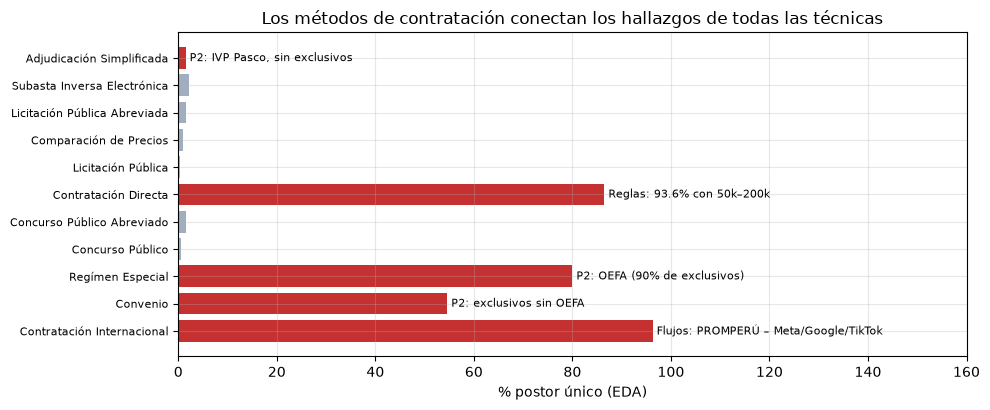

In [12]:
metodo = leer("01_EDA_KDD", "b_exploracion", "competencia_metodo").head(11)
marcas = {"Regímen Especial": "P2: OEFA (90% de exclusivos)", "Convenio": "P2: exclusivos sin OEFA",
          "Contratación Internacional": "Flujos: PROMPERÚ – Meta/Google/TikTok", "Contratación Directa": "Reglas: 93.6% con 50k–200k",
          "Adjudicación Simplificada": "P2: IVP Pasco, sin exclusivos"}
m_ = metodo.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(m_["metodo_detalle"].str[:30], m_["%_postor_unico"], color=["#c53030" if m in marcas else "#a0aec0" for m in m_["metodo_detalle"]])
for y_, (m, v) in enumerate(zip(m_["metodo_detalle"], m_["%_postor_unico"])):
    if m in marcas:
        ax.annotate(f" {marcas[m]}", (v, y_), va="center", fontsize=8)
ax.set_xlim(0, 160); ax.set_xlabel("% postor único (EDA)"); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Los métodos de contratación conectan los hallazgos de todas las técnicas")
mostrar_fig("metodos_cruce")

- **El método une todo:** Régimen Especial (OEFA), Convenio (exclusivos sin OEFA)

- Contratación Internacional (heavy hitters) y Contratación Directa (reglas más fuertes)

- **Mismos actores:** OEFA lidera (1,388 exclusivos) y la similitud intra-entidad en vecinos

- PROMPERÚ es heavy hitter con 100% de postor único

- **Lima:** baja competencia en la exploracion (26.3%) y en las reglas, aunque es donde más proveedores hay

- **Lo normativo no es riesgo:** `> 5M → Licitación Pública`, `rubro 72 → obras` responden a la ley

- **Similar no es irregular:** 96% de los pares casi idénticos son plantillas

- **Calendario:** el postor único sube en enero y diciembre; y los pares se concentran en feb–mar 2025 (64% OEFA)

- **Reincidencia (19% → 41%):** parte es real y parte es acumular historia

### 7. Escritura de resultados

Tablas en `temp/c_insights/tablas` y `web/`

In [13]:
tablas = {"valor_tecnicas": valor, "donde_corre": donde_corre, "escalamiento": escalamiento}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en temp/c_insights/: {', '.join(escritos)}")

Escrito en temp/c_insights/: valor_tecnicas, donde_corre, escalamiento


#### a. Verificación

In [14]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"

figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json) | {len(figs)} figuras: {', '.join(figs)}")

OK: 3 tablas (parquet + json) | 3 figuras: metodos_cruce, precision_vs_ahorro, spark


---
### 8. Cerrar sesión

In [15]:
spark.stop()